# Follow registers and control flow

A quantum program can keep a register, repeat a block, and use a measurement to
choose what happens next. How does the compiler represent these features while
preserving QCO's linear quantum values?

This second compiler tutorial runs independently with the
[tutorial setup](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/index.html#run-the-notebooks). Start with
[Follow a program through the compiler](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/compiler_representations.html) for an introduction to QC and QCO.

In [1]:
from IPython.display import Code, display
from qiskit.visualization import plot_distribution

from mqt.core.mlir import OutputFormat, QCProgram, compile_program, sample

## Grow a Bell state into a GHZ state

For $n$ qubits, a GHZ state is $(|0\cdots0\rangle + |1\cdots1\rangle)/\sqrt{2}$.
Apply H to the first qubit, then a controlled-X from that qubit to each of the
others.

:::{admonition} Your turn
:class: tip

Use a **register and loop** instead of writing every controlled-X by hand.
Change `width` from 3 to 2 or 4 and rerun the following cells. Predict both the
loop's iteration count and the possible measurement outcomes.
:::

In [2]:
width = 3
shots = 4096
seed = 17
assert 2 <= width <= 4

ghz_source = f"""OPENQASM 3.0;
include "stdgates.inc";
qubit[{width}] q;
bit[{width}] result;
h q[0];
for int i in [1:{width - 1}] {{
    cx q[0], q[i];
}}
result = measure q;
"""

ghz_qc = QCProgram.from_openqasm_str(ghz_source)

OpenQASM ranges include both endpoints: `[1:2]` visits 1 and 2. The loop
therefore applies `width - 1` controlled-X gates during execution. The last
statement measures each qubit into the corresponding output bit.

## Inspect the register in QC

:::{admonition} Your turn
:class: tip

Read the allocation, the loads inside the loop, and the measurement stores:
:::

In [3]:
display(Code(ghz_qc.ir, language="mlir"))

module {
  func.func @main() -> !cbit.reg<3> attributes {mqt.entry_point} {
    %alloc = memref.alloc() {mqt.register_name = "q"} : memref<3x!qc.qubit>
    %result = cbit.alloc(#cbit.init<undefined>) {mqt.register_name = "result"} : !cbit.reg<3>
    %c0 = arith.constant 0 : index
    %q = memref.load %alloc[%c0] : memref<3x!qc.qubit>
    qc.h %q : !qc.qubit
    %c1 = arith.constant 1 : index
    %c1_0 = arith.constant 1 : index
    %c2 = arith.constant 2 : index
    %c1_1 = arith.constant 1 : index
    %c3 = arith.constant 3 : index
    scf.for %arg0 = %c1 to %c3 step %c1_0 {
      %0 = arith.index_cast %arg0 : index to i64
      %c0_13 = arith.constant 0 : index
      %q_14 = memref.load %alloc[%c0_13] : memref<3x!qc.qubit>
      %q_15 = memref.load %alloc[%arg0] : memref<3x!qc.qubit>
      qc.ctrl(%q_14) targets (%q_16 = %q_15) {
        qc.x %q_16 : !qc.qubit
        qc.yield
      } : {!qc.qubit}, {!qc.qubit}
    }
    %c0_2 = arith.constant 0 : index
    %q_3 = memref.load %alloc[%c0_2] : memref<3x!qc.qubit>
    %b = qc.measure %q_3 : !qc.qubit -> i1
    %c0_4 = arith.constant 0 : index
    cbit.store %b, %result[%c0_4] : !cbit.reg<3>
    %c1_5 = arith.constant 1 : index
    %q_6 = memref.load %alloc[%c1_5] : memref<3x!qc.qubit>
    %b_7 = qc.measure %q_6 : !qc.qubit -> i1
    %c1_8 = arith.constant 1 : index
    cbit.store %b_7, %result[%c1_8] : !cbit.reg<3>
    %c2_9 = arith.constant 2 : index
    %q_10 = memref.load %alloc[%c2_9] : memref<3x!qc.qubit>
    %b_11 = qc.measure %q_10 : !qc.qubit -> i1
    %c2_12 = arith.constant 2 : index
    cbit.store %b_11, %result[%c2_12] : !cbit.reg<3>
    memref.dealloc %alloc : memref<3x!qc.qubit>
    return %result : !cbit.reg<3>
  }
}

`memref<3x!qc.qubit>` holds three qubit references in the default example.
`memref.load` retrieves one of those references; a quantum gate operates on the
referenced qubit. This is the register counterpart of scalar QC reference
semantics.

The output has type `!cbit.reg<3>`. **CBit** represents classical-bit registers
shared by QC and QCO. `qc.measure` produces an `i1` measurement result;
`cbit.store` writes it into the register that `main` returns. The imported
register's undefined initializer is safe here because the program writes every
bit before returning it.

`scf.for` is MLIR's structured counted loop. Its upper bound is **exclusive**,
so the compiler translates OpenQASM's inclusive range accordingly. An
`arith.constant` creates a classical constant; `index` is MLIR's type for
indexing and iteration in this loop.

## Follow the register through QCO

:::{admonition} Your turn
:class: tip

Predict what must change: if each quantum value has exactly one use, how can
successive loop iterations work on the same register?
:::

In [4]:
ghz_qco = ghz_qc.to_qco(copy=True)
display(Code(ghz_qco.ir, language="mlir"))

module {
  func.func @main() -> !cbit.reg<3> attributes {mqt.entry_point} {
    %c3 = arith.constant 3 : index
    %q = qtensor.alloc(%c3) {mqt.register_name = "q"} : tensor<3x!qco.qubit>
    %result = cbit.alloc(#cbit.init<undefined>) {mqt.register_name = "result"} : !cbit.reg<3>
    %c0 = arith.constant 0 : index
    %qs, %q_0 = qtensor.extract %q[%c0] : tensor<3x!qco.qubit>
    %q_1 = qco.h %q_0 : !qco.qubit
    %qs_2 = qtensor.insert %q_1 into %qs[%c0] : tensor<3x!qco.qubit>
    %c1 = arith.constant 1 : index
    %c3_3 = arith.constant 3 : index
    %0 = scf.for %arg0 = %c1 to %c3_3 step %c1 iter_args(%arg1 = %qs_2) -> (tensor<3x!qco.qubit>) {
      %qs_18, %q_19 = qtensor.extract %arg1[%c0] : tensor<3x!qco.qubit>
      %qs_20, %q_21 = qtensor.extract %qs_18[%arg0] : tensor<3x!qco.qubit>
      %controls_out, %targets_out = qco.ctrl(%q_19) targets (%q_24 = %q_21) {
        %q_25 = qco.x %q_24 : !qco.qubit
        qco.yield %q_25 : !qco.qubit
      } : ({!qco.qubit}, {!qco.qubit})
      %qs_22 = qtensor.insert %targets_out into %qs_20[%arg0] : tensor<3x!qco.qubit>
      %qs_23 = qtensor.insert %controls_out into %qs_22[%c0] : tensor<3x!qco.qubit>
      scf.yield %qs_23 : tensor<3x!qco.qubit>
    }
    %qs_4, %q_5 = qtensor.extract %0[%c0] : tensor<3x!qco.qubit>
    %q_6, %b = qco.measure %q_5 : !qco.qubit
    %qs_7 = qtensor.insert %q_6 into %qs_4[%c0] : tensor<3x!qco.qubit>
    cbit.store %b, %result[%c0] : !cbit.reg<3>
    %qs_8, %q_9 = qtensor.extract %qs_7[%c1] : tensor<3x!qco.qubit>
    %q_10, %b_11 = qco.measure %q_9 : !qco.qubit
    %qs_12 = qtensor.insert %q_10 into %qs_8[%c1] : tensor<3x!qco.qubit>
    cbit.store %b_11, %result[%c1] : !cbit.reg<3>
    %c2 = arith.constant 2 : index
    %qs_13, %q_14 = qtensor.extract %qs_12[%c2] : tensor<3x!qco.qubit>
    %q_15, %b_16 = qco.measure %q_14 : !qco.qubit
    %qs_17 = qtensor.insert %q_15 into %qs_13[%c2] : tensor<3x!qco.qubit>
    cbit.store %b_16, %result[%c2] : !cbit.reg<3>
    qtensor.dealloc %qs_17 : tensor<3x!qco.qubit>
    return %result : !cbit.reg<3>
  }
}

:::{admonition} Your turn
:class: tip

Read the quantum register's path through the program:

1. `qtensor.alloc` creates a `tensor<3x!qco.qubit>`. **QTensor** represents a
   collection of linear quantum values.
2. `qtensor.extract` transfers a qubit out of the tensor. It returns both the
   qubit and the remaining tensor, whose extracted slot is unavailable until
   filled again.
3. A gate consumes the extracted qubit and produces its successor.
4. `qtensor.insert` puts that successor back and returns an updated tensor.
5. `scf.for` carries the tensor through `iter_args`. The body receives the
   current tensor as a block argument and returns its successor with
   `scf.yield`. The loop result holds the tensor after the final iteration.
:::

Extraction does not copy a quantum state. Both the extracted qubit and the
remaining tensor follow linear semantics. A loop must carry its quantum state
through the iteration arguments rather than repeatedly capturing an earlier
value from outside the body.

`qco.measure` produces **two results**: the post-measurement qubit value and the
classical outcome. The qubit must still be inserted back into its tensor; the
classical result is stored in the CBit register. Classical values do not follow
the quantum exactly-one-use rule.

## Distinguish a loop body from executed gates

The inspection methods count gate operations, including measurements, in the
entry-point IR. A loop body is counted once, regardless of its trip count:

In [5]:
static_gates = ghz_qc.num_gates()
static_cx = ghz_qc.num_two_qubit_gates()
assert static_gates == 2 + width and static_cx == 1
print(f"Static IR: {static_gates} gates, including {static_cx} controlled-X")
print(f"This program executes: {2 * width} gates, including {width - 1} controlled-X")

Static IR: 5 gates, including 1 controlled-X
This program executes: 6 gates, including 2 controlled-X


Both totals include the `width` measurements after the loop. The runtime count
here follows directly from a loop with constant bounds. It is not a general
estimate provided by `num_gates()`. Branches and other loops can make runtime
work depend on measurement outcomes or classical inputs.

:::{admonition} Your turn
:class: tip

Compare the same program after explicit loop unrolling:
:::

Controlled-X operations after unrolling: 2


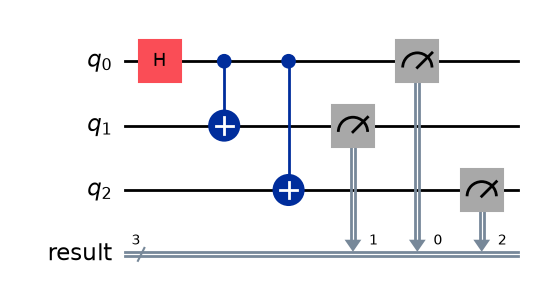

In [6]:
unrolled = ghz_qco.copy()
unrolled.unroll_quantum_loops()
unrolled_qc = unrolled.to_qc()
assert unrolled_qc.num_two_qubit_gates() == width - 1
print(f"Controlled-X operations after unrolling: {unrolled_qc.num_two_qubit_gates()}")
unrolled_qc.to_qiskit().draw("mpl")

Unrolling duplicates the body for the known iterations. It changes the
representation, not the algorithm. Keeping loops can keep IR compact; some
output formats or target-address requirements need the iterations exposed. The
[target notebook](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/hardware_compilation.html) explains how output and hardware
constraints guide compilation.

## Check the observable result

The QCO sampler interprets supported structured programs directly. With 4096
shots, approximately half the results should be all zeros and half all ones:

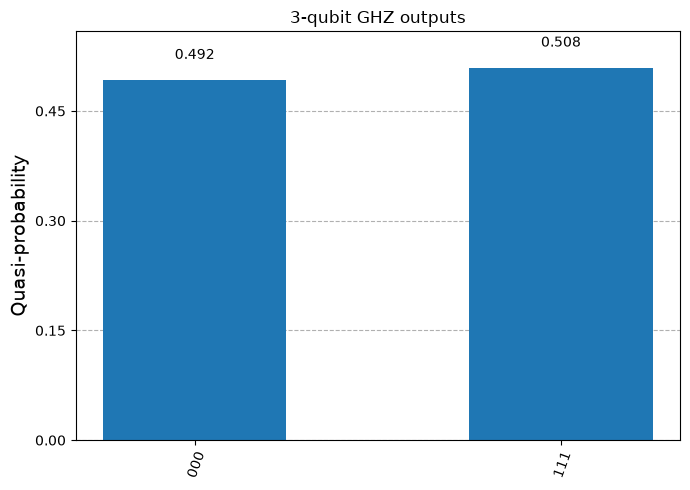

In [7]:
ghz_counts = sample(ghz_qco, shots=shots, seed=seed)
zeros, ones = "0" * width, "1" * width
assert set(ghz_counts) == {zeros, ones}
assert sum(ghz_counts.values()) == shots
assert abs(ghz_counts[zeros] / shots - 0.5) < 0.05
plot_distribution(ghz_counts, title=f"{width}-qubit GHZ outputs")

The keys describe the returned classical register, with its highest-index bit on
the left. The sampler reports measured outputs; it does not display a
statevector. A fixed nonzero seed makes this experiment reproducible, but
statistical checks should not depend on a particular histogram.

:::{admonition} Your turn
:class: tip

**Experiment: change the register width**

Try `width = 2` and `width = 4` in the parameter cell and rerun the GHZ section.
The structured body still contains one controlled-X, but it executes once or
three times. The histogram still has two outcomes, now with two or four bits.
:::

:::{admonition} Your turn
:class: tip

Compare the two widths by generating and sampling each program:
:::

In [8]:
for test_width in (2, 4):
    variant = ghz_source.replace(f"[{width}]", f"[{test_width}]").replace(f"[1:{width - 1}]", f"[1:{test_width - 1}]")
    counts = sample(variant, shots=shots, seed=seed)
    assert set(counts) == {"0" * test_width, "1" * test_width}
    assert sum(counts.values()) == shots
    assert abs(counts["0" * test_width] / shots - 0.5) < 0.05
    print(f"Width {test_width}: {counts}")

Width 2: {'00': 2015, '11': 2081}
Width 4: {'0000': 2015, '1111': 2081}


## Use a measurement to choose the next gate

A **classical correction** prepares zero even when the first measurement is
random.

:::{admonition} Your turn
:class: tip

Start with H, measure, and apply X only if the outcome is 1. What should
a second measurement return?
:::

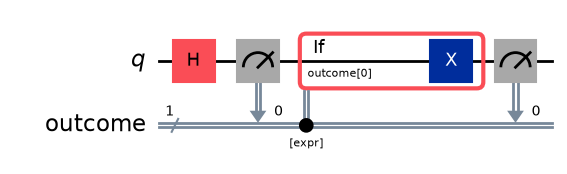

In [9]:
feedback_source = """OPENQASM 3.0;
include "stdgates.inc";
qubit q;
bit outcome;
h q;
outcome = measure q;
if (outcome) {
    x q;
}
outcome = measure q;
"""

feedback_qc = QCProgram.from_openqasm_str(feedback_source)
feedback_qc.to_qiskit(copy=True).draw("mpl")

The output register is overwritten by the second measurement. The first result
controls the correction but is not a second returned output bit.

:::{admonition} Your turn
:class: tip

Inspect the branch in QCO:
:::

In [10]:
feedback_qco = feedback_qc.to_qco(copy=True)
display(Code(feedback_qco.ir, language="mlir"))

module {
  func.func @main() -> !cbit.reg<1> attributes {mqt.entry_point} {
    %q = qco.alloc : !qco.qubit
    %outcome = cbit.alloc(#cbit.init<undefined>) {mqt.register_name = "outcome"} : !cbit.reg<1>
    %q_0 = qco.h %q : !qco.qubit
    %q_1, %b = qco.measure %q_0 : !qco.qubit
    %c0 = arith.constant 0 : index
    cbit.store %b, %outcome[%c0] : !cbit.reg<1>
    %c0_2 = arith.constant 0 : index
    %b_3 = cbit.load %outcome[%c0_2] : !cbit.reg<1>
    %linearResults = qco.if %b_3 args(%q_7 = %q_1) -> (!qco.qubit) {
      %q_8 = qco.x %q_7 : !qco.qubit
      qco.yield %q_8 : !qco.qubit
    } else args(%q_7 = %q_1) {
      qco.yield %q_7 : !qco.qubit
    }
    %q_4, %b_5 = qco.measure %linearResults : !qco.qubit
    %c0_6 = arith.constant 0 : index
    cbit.store %b_5, %outcome[%c0_6] : !cbit.reg<1>
    qco.sink %q_4 : !qco.qubit
    return %outcome : !cbit.reg<1>
  }
}

`qco.if` receives a classical condition and transfers the post-measurement qubit
into the selected branch. The true branch applies X; the false branch forwards
the qubit unchanged. Each branch yields the qubit value that execution should
use next. The second measurement consumes the branch result.

| Operation  | Condition             | What happens                                                           |
| ---------- | --------------------- | ---------------------------------------------------------------------- |
| `qco.ctrl` | Quantum control qubit | Applies a coherent controlled operation, without measuring the control |
| `qco.if`   | Classical value       | Executes one branch and carries its quantum values to the result       |

Generic `scf.if` can represent classical branching, but quantum branches use
`qco.if` to express these ownership transfers. SCF loops carry quantum values
through their iteration arguments, as in the GHZ example.

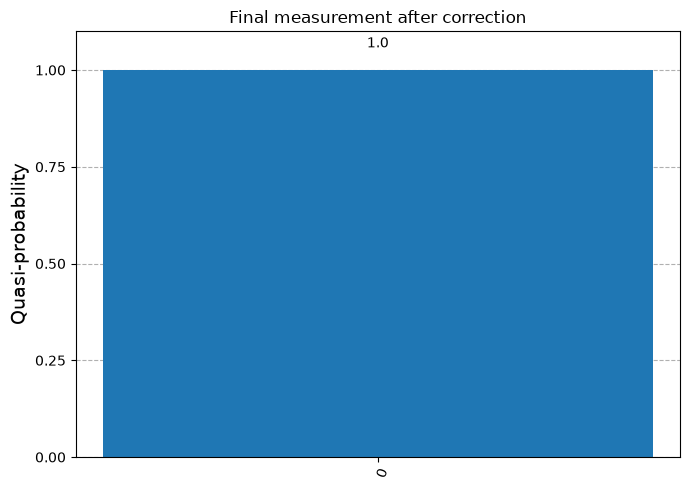

In [11]:
corrected_counts = sample(feedback_qco, shots=shots, seed=seed)
assert corrected_counts == {"0": shots}
plot_distribution(corrected_counts, title="Final measurement after correction")

Every shot returns zero. Use sampling for this experiment: the convenience
`simulate()` function that returns a dense statevector does not support
mid-circuit feedback. See the [DD guide](https://mqt.readthedocs.io/projects/core/en/stable/dd_package.html) for lower-level
simulation interfaces.

:::{admonition} Your turn
:class: tip

**Experiment: remove the correction**

Delete the `if` block, or run the variant below. The second measurement repeats
the first outcome because nothing changes the measured qubit in between. Its
outcome is random across shots, even though the two measurements within a shot
agree.
:::

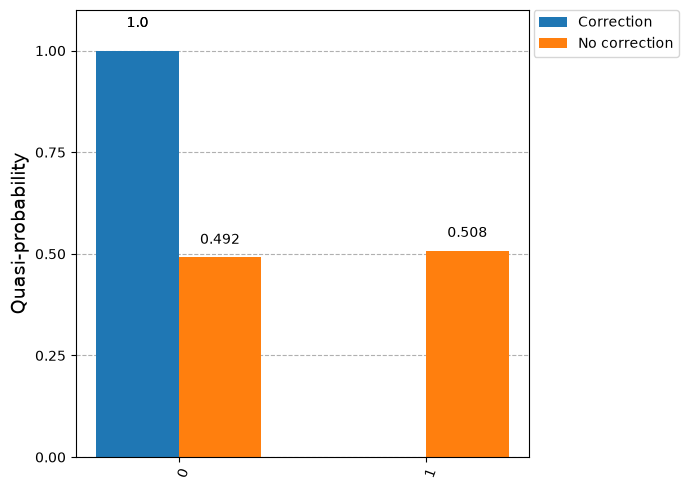

In [12]:
uncorrected_source = feedback_source.replace("if (outcome) {\n    x q;\n}\n", "")
uncorrected_counts = sample(uncorrected_source, shots=shots, seed=seed)
assert set(uncorrected_counts) == {"0", "1"}
assert sum(uncorrected_counts.values()) == shots
assert abs(uncorrected_counts["0"] / shots - 0.5) < 0.05
plot_distribution([corrected_counts, uncorrected_counts], legend=["Correction", "No correction"])

Continue with [Compile for hardware constraints](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/hardware_compilation.html) to compile against explicit hardware
constraints. For larger structured examples, explore
[iterative QPE](https://mqt.readthedocs.io/projects/core/en/stable/benchmarks.html#quantum-phase-estimation) and
[repeat until success](https://mqt.readthedocs.io/projects/core/en/stable/benchmarks.html#repeat-until-success). The
[QTensor](https://mqt.readthedocs.io/projects/core/en/stable/mlir/QTensor.html), [CBit](https://mqt.readthedocs.io/projects/core/en/stable/mlir/CBit.html), and [OpenQASM](https://mqt.readthedocs.io/projects/core/en/stable/mlir/OpenQASM.html)
references describe the operations and supported input forms in detail.